<a href="https://colab.research.google.com/github/yeugeneu/IAT360-CV-13-Cloud-Type-Classifier/blob/Data-Preprocessing/Cloud_type_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Preprocessing
We have to convert the dataset into that acceptable by YOLO.
- Heirarchy of folders should be the one accepted by YOLO
- Labels format should be object detection for YOLOv8
```
class x_center y_center width height
```

- Labels files should be .txt files with an object in the image per row

1. Make sure you download and extract [Roboflow Cloud Computer Vision Model dataset](https://universe.roboflow.com/ip2-kbjz5/cloud-qthye/browse?queryText=&pageSize=100&startingIndex=0&browseQuery=true)

2. Rename the folder to 'CloudDataset'

3. Below steps will guide you through converting the original dataset to the folder hierarchy we wish to use


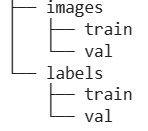

## Import required libraries

In [2]:
import glob
import os
import random
import shutil
from PIL import Image
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics.data.utils import visualize_image_annotations

## Re-organize all Dataset images/labels

#### Oragnizing Dataset from Roboflow data source

## Load all images and labels located inside the "CloudDataset" folder

In [3]:
# Set train, validate, and test dataset paths
train_dir_img = 'CloudDataset/train/images'
train_dir_lbl = 'CloudDataset/train/labels'

val_dir_img = 'CloudDataset/valid/images'
val_dir_lbl = 'CloudDataset/valid/labels'

test_dir_img = 'CloudDataset/test/images'
test_dir_lbl = 'CloudDataset/test/labels'

Create new root folder called "All_data", with 2 child folders "images" and "labels"

In [4]:
os.makedirs('All_data/images')
os.makedirs('All_data/labels')

Copy the label txt files and image jpg files to the new folders created

In [5]:
#set the paths to labels and images directory for All data
label_dir= "All_data/labels"
image_dir= "All_data/images"

In [6]:
# Source directories mapped to their target categories
image_sources = [train_dir_img, val_dir_img, test_dir_img]
label_sources = [train_dir_lbl, val_dir_lbl, test_dir_lbl]

# Copy and process all images to image_dir
for src_dir in image_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                try:
                    img_path = os.path.join(src_dir, file)
                    image = Image.open(img_path)
                    image = image.convert("RGB")
                    new_filename = os.path.splitext(file)[0] + ".jpg"
                    image.save(os.path.join(image_dir, new_filename), "JPEG")
                except Exception as e:
                    print(f"Error processing image {file}: {e}")

# Copy all label files to label_dir
for src_dir in label_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith(".txt"):
                shutil.copy(os.path.join(src_dir, file), os.path.join(label_dir, file))

Take a look at the first 4 images in the "Final_data/images" folder to make sure the images are moved correctly

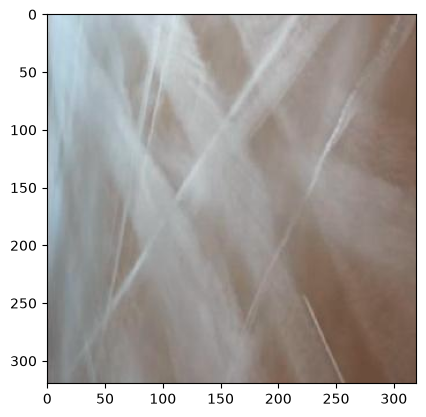

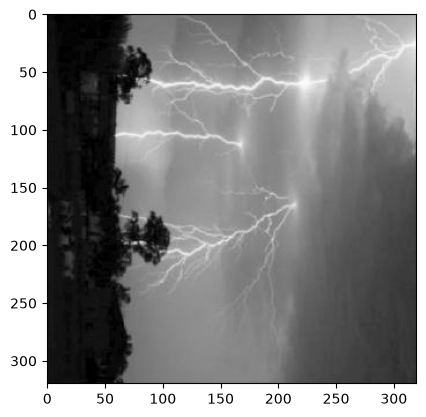

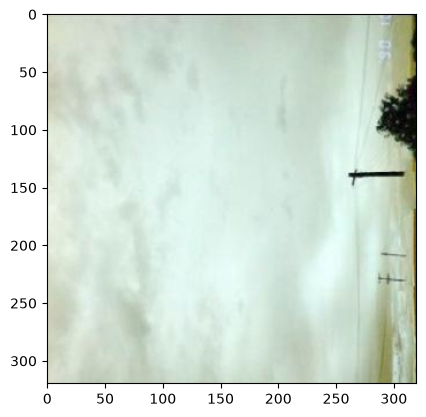

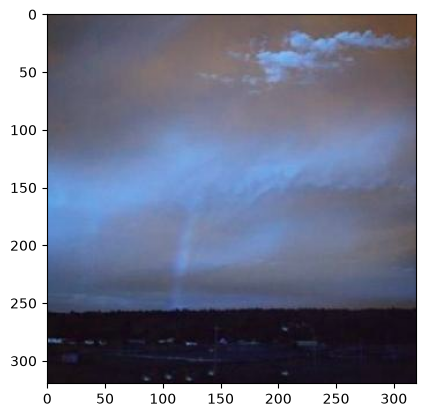

In [7]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(os.path.join(image_dir))):
    img = cv2.imread(os.path.join(image_dir, image), 1)
    plt.imshow(img)
    plt.show()

    if idx == 3:
        break

### Organize group memeber images

Download the images collected from all 4 group members ([FirstName]_Cloud_Data_Labeled) located in this link https://1sfu-my.sharepoint.com/:f:/r/personal/yya6_sfu_ca/Documents/CV%20Project%20Group%2013?d=w11d6cbb929af48b29ee060bcf9c1bf78&csf=1&web=1&e=WJnLSs


In [32]:
# creates Members_Dataset and moves every folder ending in _CloudData_Labeled
import os, shutil

os.makedirs("Members_Dataset", exist_ok=True)

for name in os.listdir("."):
    if name.endswith("_CloudData_Labeled") and os.path.isdir(name):
        shutil.move(name, os.path.join("Members_Dataset", name))
        print("moved", name)

# show what's inside so you can check the structure
for name in os.listdir("Members_Dataset"):
    print(name, "->", os.listdir(os.path.join("Members_Dataset", name)))

moved Dalena_CloudData_Labeled
moved Eugene_CloudData_Labeled
Dalena_CloudData_Labeled -> ['classes.txt', 'images', 'labels', 'notes.json']
Eugene_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels']


In [33]:
# Set all paths to the dataset
eugene_dir_img = 'Members_Dataset/Eugene_CloudData_Labeled/images'
eugene_dir_lbl = 'Members_Dataset/Eugene_CloudData_Labeled/labels'

dalena_dir_img = 'Members_Dataset/Dalena_CloudData_Labeled/images'
dalena_dir_lbl = 'Members_Dataset/Dalena_CloudData_Labeled/labels'

martina_dir_img = 'Members_Dataset/Martina_CloudData_Labeled/images'
martina_dir_lbl = 'Members_Dataset/Martina_CloudData_Labeled/labels'

marielle_dir_img = 'Members_Dataset/Marielle_CloudData_Labeled/images'
marielle_dir_lbl = 'Members_Dataset/Marielle_CloudData_Labeled/labels'

Copy the label txt files and image jpg files to the new folders created

In [34]:
#set the paths to labels and images directory for All data
label_dir= "All_data/labels"
image_dir= "All_data/images"

Every image from every member gets converted to RGB .jpg and saved into All_data/images.
Every label .txt from every member gets copied into All_data/labels.
Original Cloud dataset in it as well


In [35]:
# Source directories mapped to their target categories
image_sources = [eugene_dir_img, dalena_dir_img, martina_dir_img, marielle_dir_img]
label_sources = [eugene_dir_lbl, dalena_dir_lbl, martina_dir_lbl, marielle_dir_lbl]

# Copy and process all images to image_dir
for src_dir in image_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                try:
                    img_path = os.path.join(src_dir, file)
                    image = Image.open(img_path)
                    image = image.convert("RGB")
                    new_filename = os.path.splitext(file)[0] + ".jpg"
                    image.save(os.path.join(image_dir, new_filename), "JPEG")
                except Exception as e:
                    print(f"Error processing image {file}: {e}")

# Copy all label files to label_dir
for src_dir in label_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith(".txt"):
                shutil.copy(os.path.join(src_dir, file), os.path.join(label_dir, file))

In [36]:
print(len(os.listdir("All_data/images")), len(os.listdir("All_data/labels")))

11204 11204


In [38]:
from collections import Counter
print(Counter(n.split("_")[0] if "_" in n else "other" for n in names).most_common(10))

[('Cs-N074', 6), ('Ac-N149', 6), ('As-N146', 6), ('Ns-N205', 6), ('Cs-N262', 6), ('Cs-N003', 6), ('Cc-N109', 6), ('Sc-N175', 6), ('Sc-N311', 6), ('Ct-N060', 6)]


## Check for missing files

In [12]:
# Rename files in image_dir and label_dir replacing '.' with '-'
for folder in [image_dir, label_dir]:
    for filename in os.listdir(folder):
        filepath = os.path.join(folder, filename)
        if os.path.isfile(filepath):
            name, ext = os.path.splitext(filename)
            if '.' in name:
                new_name = name.replace('.', '-') + ext
                os.rename(filepath, os.path.join(folder, new_name))

#The lists of all the images and labels for train and validation set:
all_images=glob.glob(os.path.join(image_dir,'*.jpg'))
all_labels=glob.glob(os.path.join(label_dir,'*.txt'))


all image number should match all label number

In [ ]:
print("(Images)", len(all_images), " = ", len(all_labels), " (Labels)")

(Images) 11204  =  11204  (Labels)


## Randomly pick an image and a label to check if annotation can be populated

Visualizing: Sc-N318_jpg-rf-56f8c034f8595c2ac29e0f66af374184.jpg


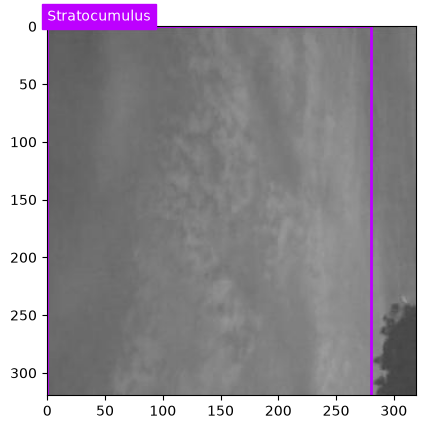

Visualizing: As-N084_jpg-rf-365e146e7b2d51d3dc67d5832964ecba.jpg


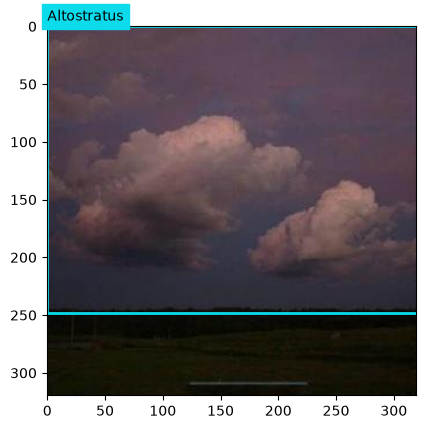

Visualizing: Ns-N068_jpg-rf-6459e00eb408ec9d833d71c392128e05.jpg


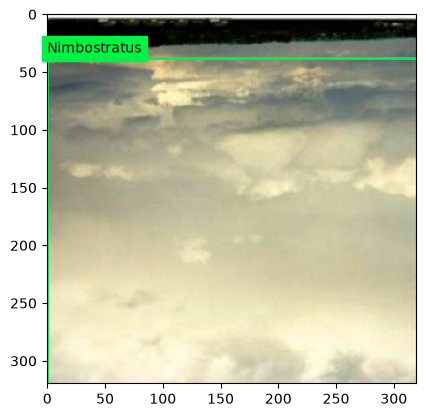

In [ ]:
# Get a list of all images
image_files = os.listdir("All_data/images")

# Pick 3 random images
random_images = random.sample(image_files, 3)

# Visualize each of the 3 selected images
for random_image in random_images:
    # Construct matching image and label paths
    base_name = os.path.splitext(random_image)[0]
    random_image_path = os.path.join("All_data/images", random_image)
    random_label_path = os.path.join("All_data/labels", f"{base_name}.txt")

    # Visualize
    print(f"Visualizing: {random_image}")
    visualize_image_annotations(
        random_image_path,
        random_label_path,
        class_map,
    )

## Check the Data balance

class_name
Stratocumulus    1524
Cirrostratus     1260
Nimbostratus     1237
Cirrocumulus     1211
Cumulonimbus     1010
Altocumulus       952
Contrails         945
Stratus           899
Altostratus       817
Cumulus           784
Cirrus            622
Name: count, dtype: int64


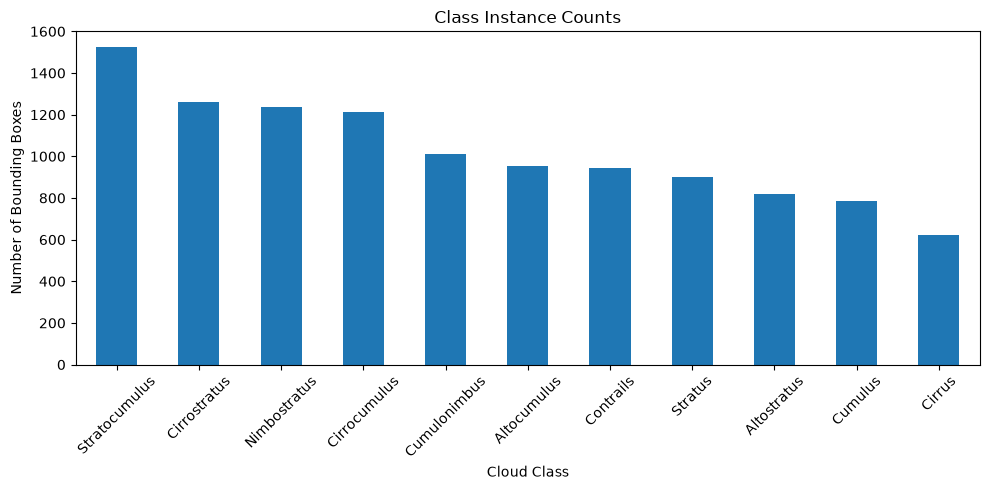

In [ ]:
# 1. Define your class mapping dictionary
class_map = {
    0: "Altocumulus",
    1: "Altostratus",
    2: "Cirrocumulus",
    3: "Cirrostratus",
    4: "Cirrus",
    5: "Contrails",
    6: "Cumulonimbus",
    7: "Cumulus",
    8: "Nimbostratus",
    9: "Stratocumulus",
    10: "Stratus"
}

# 2. Gather label annotation files
labels_dir = "All_data/labels"
annotation_files = glob.glob(os.path.join(labels_dir, "*.txt"))

records = []
for file in annotation_files:
    with open(file, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                records.append(int(parts[0]))

# Create DataFrame
df = pd.DataFrame(records, columns=['class_id'])

# Map class IDs to names
df['class_name'] = df['class_id'].map(class_map)

# Value counts table
print(df['class_name'].value_counts())

# Plot distribution
df['class_name'].value_counts().plot(kind='bar', figsize=(10, 5), title="Class Instance Counts")
plt.xlabel("Cloud Class")
plt.ylabel("Number of Bounding Boxes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Split and re-organize all images and labels into train, val, and test sub-folder with 80-10-10 split

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Load the sorted lists of all images and matching labels
# Sorting ensures that images and labels pair up correctly (e.g., image[i] matches label[i])
images_dir = "All_data/images"
labels_dir = "All_data/labels"

# Get all file names and sort them alphabetically
image_files = sorted(os.listdir(images_dir))
label_files = sorted(os.listdir(labels_dir))

# Double check we are matching base names (e.g., image_01.jpg maps to image_01.txt)
# We'll filter to make sure we only split perfectly matching image-label pairs
valid_images = []
valid_labels = []

for img in image_files:
    base_name = os.path.splitext(img)[0]
    label_name = f"{base_name}.txt"
    if label_name in label_files:
        valid_images.append(os.path.join(images_dir, img))
        valid_labels.append(os.path.join(labels_dir, label_name))

# 2. Split into 80% train+validation and 20% test set
X_train_val, X_test, y_train_val, y_test = train_test_split(
    valid_images,
    valid_labels,
    test_size=0.20,
    random_state=42
)

# 3. Split the 80% train+validation set into 75% train and 25% validation
# This results in: 60% Train, 20% Validation, and 20% Test
X_train, X_validation, y_train, y_validation = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42
)

print(f"Split completed:")
print(f"  - Train set size: {len(X_train)} pairs")
print(f"  - Validation set size: {len(X_validation)} pairs")
print(f"  - Test set size: {len(X_test)} pairs")


Split completed:
  - Train set size: 6722 pairs
  - Validation set size: 2241 pairs
  - Test set size: 2241 pairs


In [ ]:
import os
import shutil

# Define the target subdirectories
splits = ['train', 'val', 'test']
for split in splits:
    os.makedirs(os.path.join("All_data/images", split), exist_ok=True)
    os.makedirs(os.path.join("All_data/labels", split), exist_ok=True)

# Helper function to move a list of files to their respective folder
def move_files(file_paths, destination_folder):
    for path in file_paths:
        if os.path.exists(path):
            filename = os.path.basename(path)
            shutil.move(path, os.path.join(destination_folder, filename))

# Move image sets
move_files(X_train, "All_data/images/train")
move_files(X_validation, "All_data/images/val")
move_files(X_test, "All_data/images/test")

# Move label sets
move_files(y_train, "All_data/labels/train")
move_files(y_validation, "All_data/labels/val")
move_files(y_test, "All_data/labels/test")

# Verify counts in new structured folders
print("\nPhysical Split Verification:")
for split in splits:
    img_count = len(os.listdir(os.path.join("All_data/images", split)))
    lbl_count = len(os.listdir(os.path.join("All_data/labels", split)))
    print(f"  - {split.capitalize()} Set: {img_count} images | {lbl_count} labels")


Moving images...
Moving labels...

Physical Split Verification:
  - Train Set: 6722 images | 6722 labels
  - Val Set: 2241 images | 2241 labels
  - Test Set: 2241 images | 2241 labels


# Model Training

In [ ]:
cloud_labels = {
    0: "Altocumulus",
    1: "Altostratus",
    2: "Cirrocumulus",
    3: "Cirrostratus",
    4: "Cirrus",
    5: "Contrails",
    6: "Cumulonimbus",
    7: "Cumulus",
    8: "Nimbostratus",
    9: "Stratocumulus",
    10: "Stratus"
}

# Model Evaluation